# Pipeline IPF: De-novo integration vs. mapping with scArches

In [1]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [2]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [3]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [4]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

## 0. Import all relevant datasets

First run notebook: LCA_prep_healthy
- Set labels (cell type harmonization)
- scran normalize counts (not log-transformed!)

query_data:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

source_adata:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

atlas_data:
- .X: subsetted raw count data for reference atlas (only the 2000 HVGs)

In [5]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/IPF_labeled_normalized.h5ad")

In [6]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")

In [7]:
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")
atlas_data.var.index = atlas_data.var.gene_ids

## 1. Perform de-novo integration

### 1.1 Preparation

In [8]:
source_adata.var = source_adata.var.set_index("gene_ids")

In [9]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [10]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [11]:
combined_data.var["highly_variable-0"].fillna(False, inplace=True)

Create two datasets: 
- combined_data: recalculate hvgs and take top 2000
- combined_data_ref_hvg: take 2000 hvg calculated on reference atlas

In [12]:
combined_data_ref_hvg = combined_data[:,combined_data.var["highly_variable-0"]].copy()

In [13]:
combined_data_ref_hvg.X = combined_data_ref_hvg.layers['counts'].copy()

For further learning get back raw counts for query data

In [14]:
query_data.X = query_data.layers['counts'].copy()

Recalculate highly variable genes

In [15]:
# function to calculate variances on *sparse* matrix
def vars(a, axis=None):
    """ Variance of sparse matrix a
    var = mean(a**2) - mean(a)**2
    """
    a_squared = a.copy()
    a_squared.data **= 2
    return a_squared.mean(axis) - np.square(a.mean(axis))

calculate mean, variance, dispersion per gene:

In [16]:
means = np.mean(combined_data.X, axis=0)

In [17]:
variances = vars(combined_data.X, axis=0)

In [18]:
dispersions = variances / means

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in true_divide
  """Entry point for launching an IPython kernel.


set min_mean cutoff (base this on the plot). We do not want to include the leftmost noisy genes that have high dispersions due to low means.

In [19]:
min_mean = 0.06

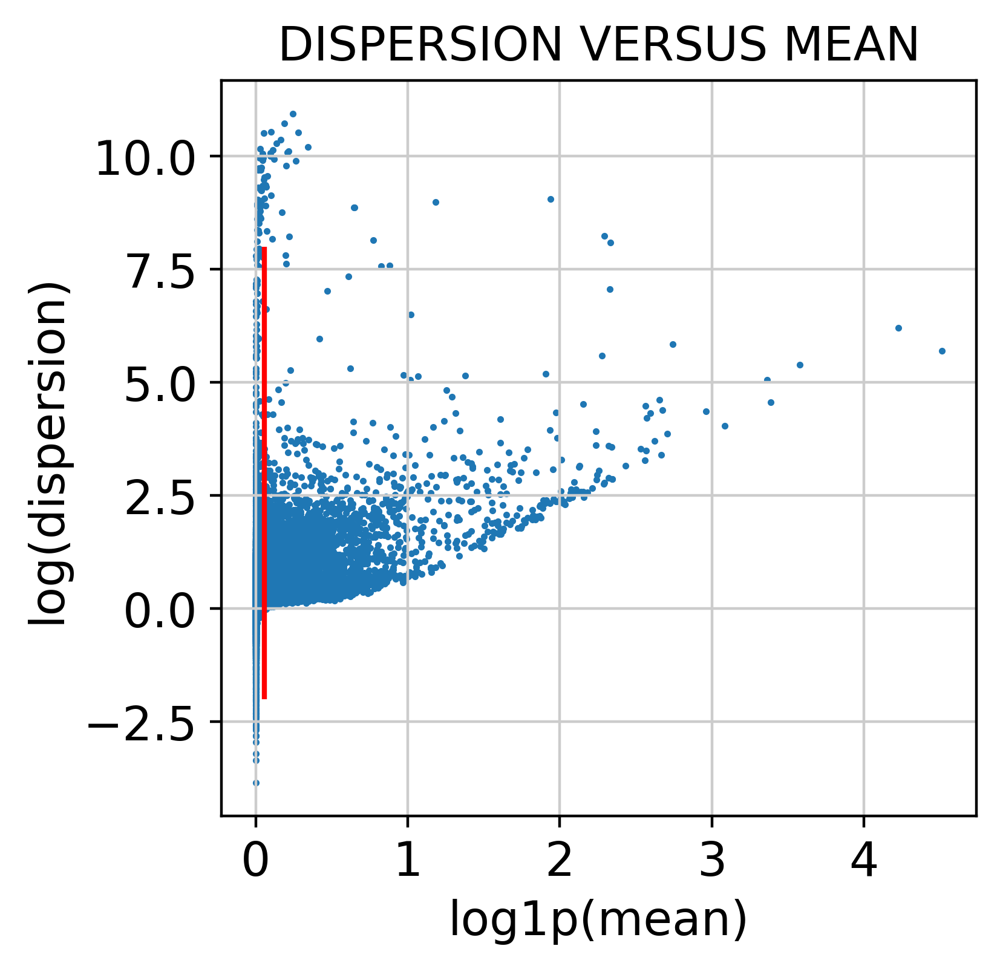

In [20]:
# plot mean versus dispersion plot:
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1,
    
)
plt.vlines(x=np.log1p(min_mean),ymin=-2,ymax=8,color='red')
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

log-transform data:

In [21]:
sc.pp.log1p(combined_data)

now calculate highly variable genes:

In [22]:
sc.pp.highly_variable_genes(combined_data, batch_key="dataset", min_mean=min_mean, flavor="cell_ranger", n_top_genes=2000)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/pandas/core/indexing.py:1732: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

In [23]:
combined_data.raw = combined_data

check selection of genes:

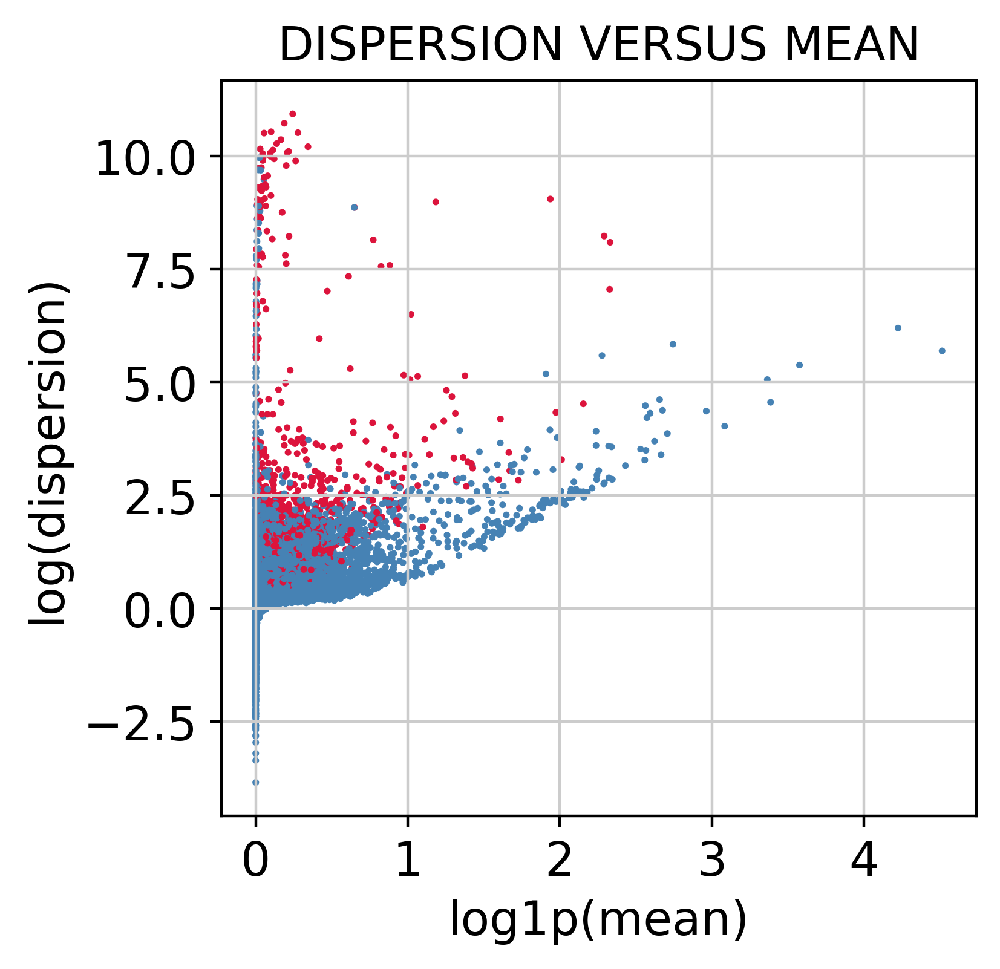

In [24]:
boolean_to_color = {
    True: "crimson",
    False: "steelblue",
}  # make a dictionary that translates the boolean to colors
hvg_colors = combined_data.var.highly_variable.map(boolean_to_color)  # 'convert' the boolean
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1, c=hvg_colors
)
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

Subset data to the calculated top 2000 highly variable genes

In [25]:
combined_data = combined_data[:,combined_data.var.highly_variable].copy()

In [26]:
np.unique(query_data.obs.study)

array(['Banovich_Kropski_2020', 'Kaminski_2020', 'Misharin_Budinger_2018',
       'Sheppard_2020'], dtype=object)

Check if additional genes from adams/kamisnki dataset were not selected as hvgs

In [27]:
genes_to_keep = pd.read_csv("/storage/groups/ml01/workspace/jan.domke/Data/Homo_sapiens_GRCh38_84_gene_ids_to_keep_cellrangerbased.txt", header=None)

In [28]:
genes_to_keep.rename(columns={0:"gene_id"},inplace=True)
genes_to_keep = genes_to_keep.gene_id.tolist()

In [29]:
kaminski = query_data[query_data.obs.study=="Kaminski_2020"]

In [30]:
not_cell_ranger = kaminski.var.index[~kaminski.var.index.isin(genes_to_keep)]

In [31]:
np.sum(combined_data.var.index.isin(not_cell_ranger))

0

Go back to raw counts

In [32]:
combined_data.X = combined_data.layers["counts"].copy()

In [33]:
np.unique(source_adata.obs.scanvi_label)

array(['AT1', 'AT2', 'B cell lineage', 'Basal', 'Bronchial Vessel 1',
       'Bronchial Vessel 2', 'Dendritic cells', 'EC arterial',
       'EC capillary', 'EC venous', 'Fibroblast lineage',
       'Innate lymphoid cell NK', 'KRT5- KRT17+ epithelial',
       'Lymphatic EC', 'Macrophages', 'Mast cells', 'Megakaryocytes',
       'Mesothelium', 'Monocytes', 'Multiciliated lineage',
       'Neutrophilic', 'Proliferating cells', 'Rare', 'Secretory',
       'Smooth muscle', 'Squamous', 'Submucosal Secretory',
       'T cell lineage', 'unlabeled'], dtype=object)

### 1.2 scVI and scANVI model with newly calculated HVGs

In [15]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

In [35]:
sca.dataset.setup_anndata(combined_data, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             
INFO     Using labels from adata.obs["scanvi_label"]                                         
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 30 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
INFO     Please do not further modify adata until model is trained.                          


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [36]:
scvi_model = sca.models.SCVI(
    combined_data,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

In [37]:
scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 413/500:  83%|████████▎ | 413/500 [8:41:45<1:49:54, 75.80s/it, loss=570, v_num=1]


In [38]:
scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI")

In [39]:
scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI", combined_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 30 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [40]:
combined_data.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [41]:
sc.pp.neighbors(combined_data, use_rep="X_scVI")
sc.tl.leiden(combined_data)
sc.tl.umap(combined_data)

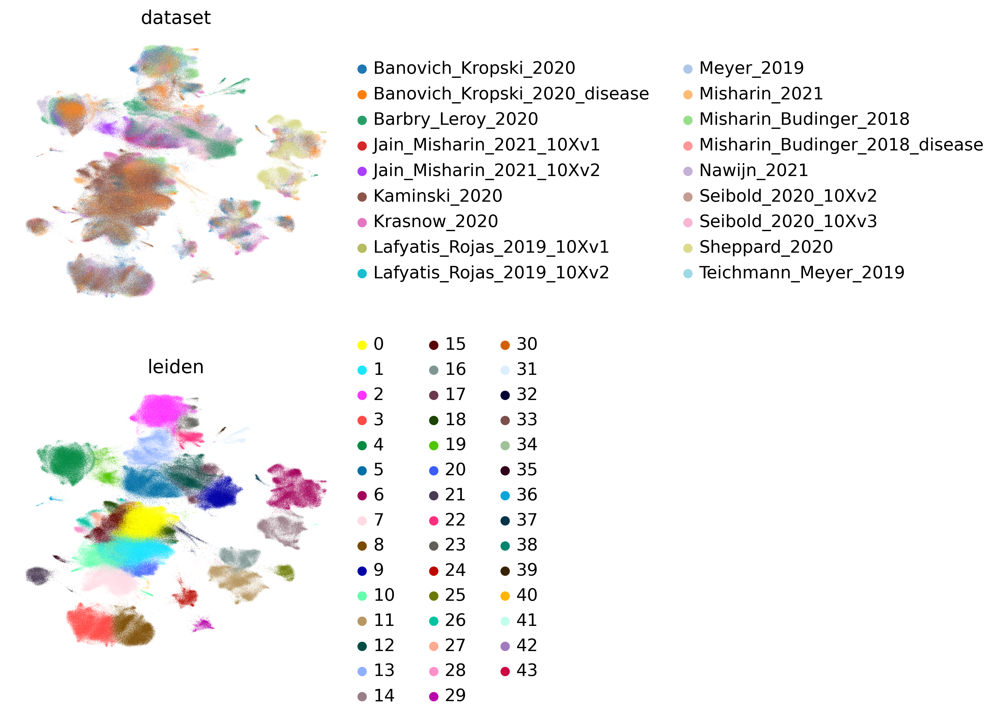

In [42]:
sc.pl.umap(
    combined_data,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

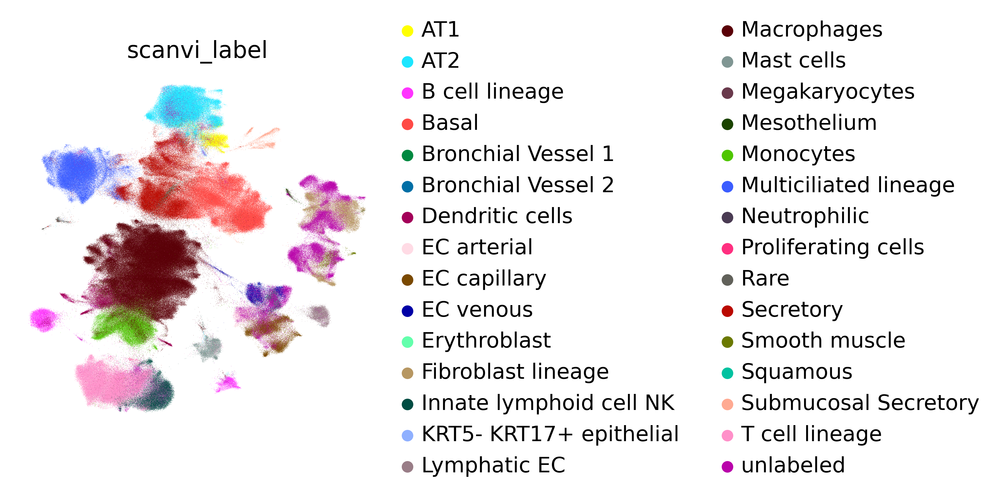

In [43]:
sc.pl.umap(combined_data, color=cell_type_key, frameon=False)

In [44]:
scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=combined_data)

In [45]:
scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [9:18:21<00:00, 167.51s/it, loss=671, v_num=1]  


In [46]:
scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI")

In [47]:
#scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI", combined_data)

In [48]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Labelled Indices:  881795
Unlabelled Indices:  77584


In [49]:
combined_data.obs["C_scANVI"] = scANVI_model.predict(combined_data)
combined_data.obsm["X_scANVI"] = scANVI_model.get_latent_representation(combined_data)

In [50]:
sc.pp.neighbors(combined_data, use_rep="X_scANVI")
sc.tl.umap(combined_data)

... storing 'C_scANVI' as categorical


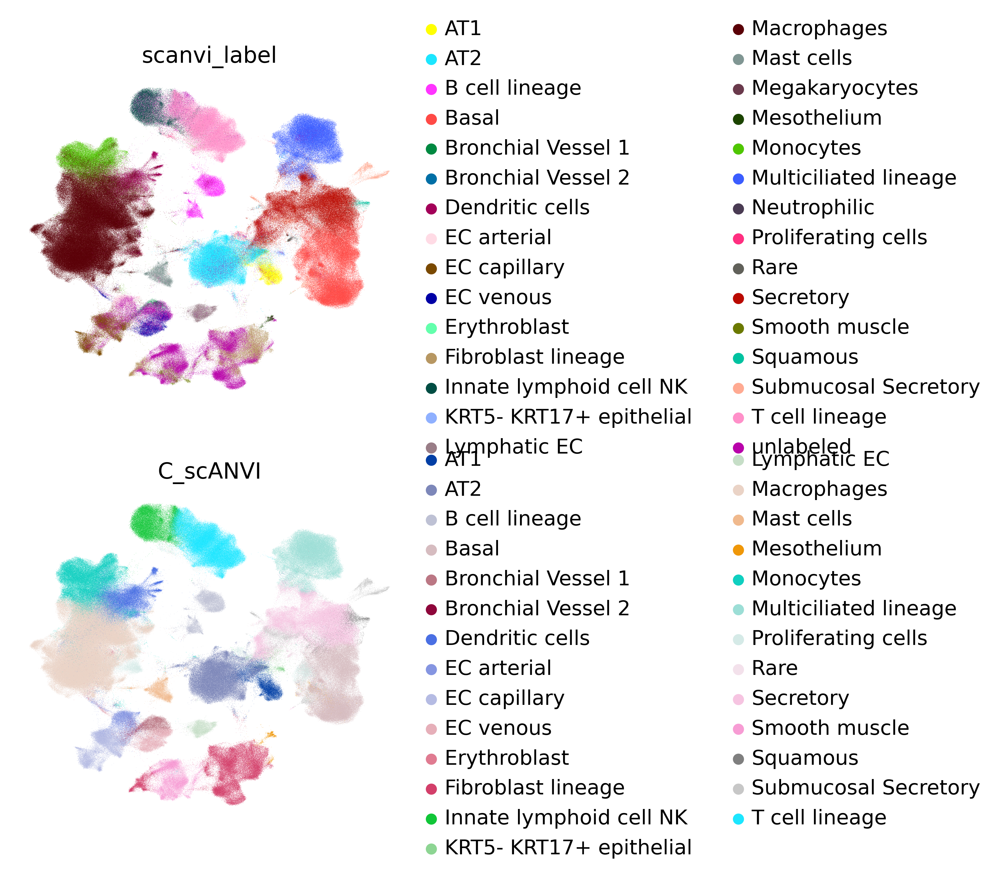

In [51]:
sc.pl.umap(combined_data, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [52]:
df = combined_data.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

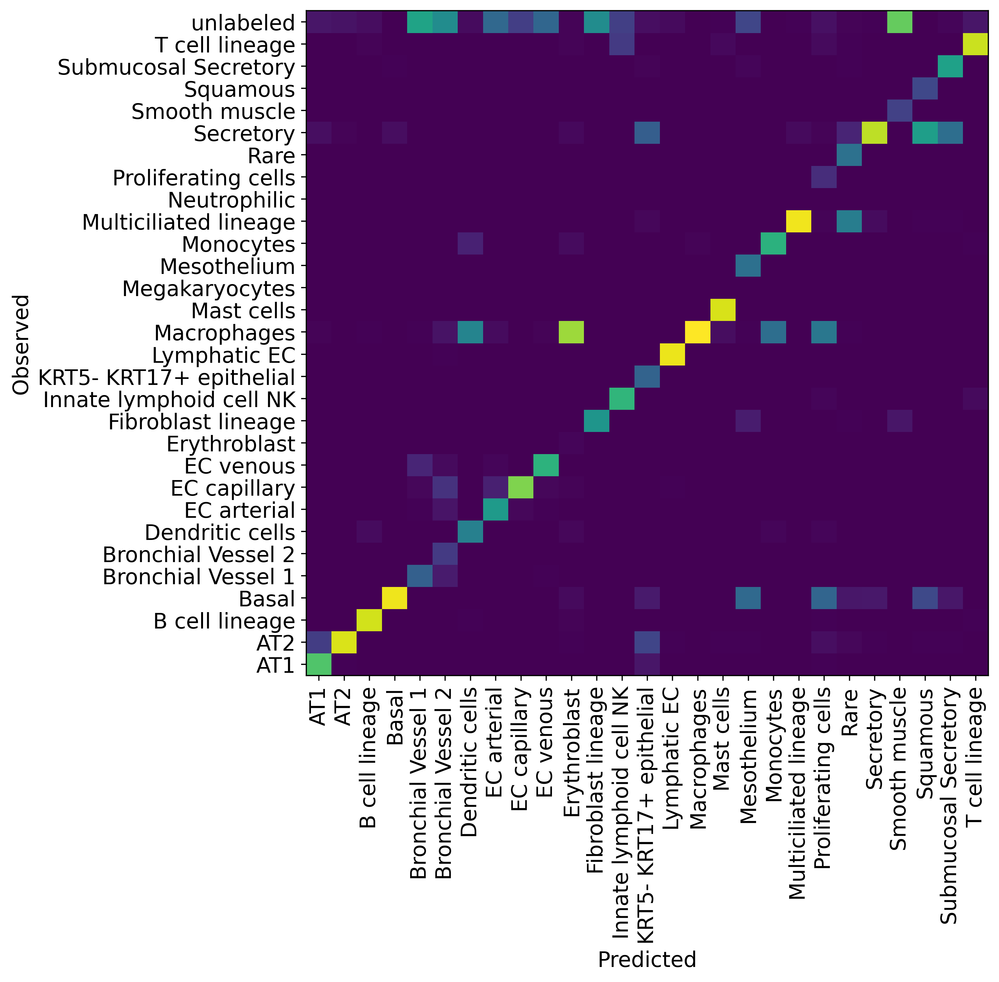

In [53]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [54]:
combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo.h5ad")

### 1.3 scVI and scANVI model with old reference HVGs

In [17]:
sca.dataset.setup_anndata(combined_data_ref_hvg, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             
INFO     Using labels from adata.obs["scanvi_label"]                                         
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 30 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
INFO     Please do not further modify adata until model is trained.                          


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [18]:
scvi_model_ref_hvg = sca.models.SCVI(
    combined_data_ref_hvg,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

In [ ]:
scvi_model_ref_hvg.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 401/500:  80%|████████  | 400/500 [17:55:57<4:53:37, 176.17s/it, loss=621, v_num=1] 

In [ ]:
scvi_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI_ref_hvg")

In [16]:
scvi_model_ref_hvg = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 30 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [17]:
combined_data_ref_hvg.obsm["X_scVI"] = scvi_model_ref_hvg.get_latent_representation()

In [18]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scVI")
sc.tl.leiden(combined_data_ref_hvg)
sc.tl.umap(combined_data_ref_hvg)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical


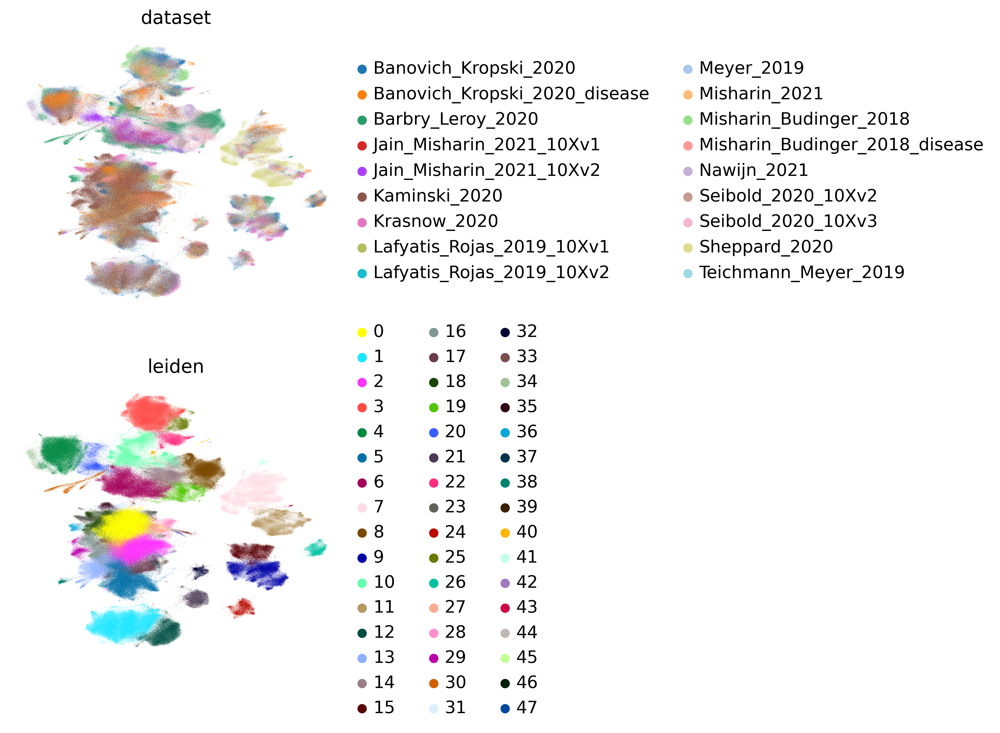

In [19]:
sc.pl.umap(
    combined_data_ref_hvg,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

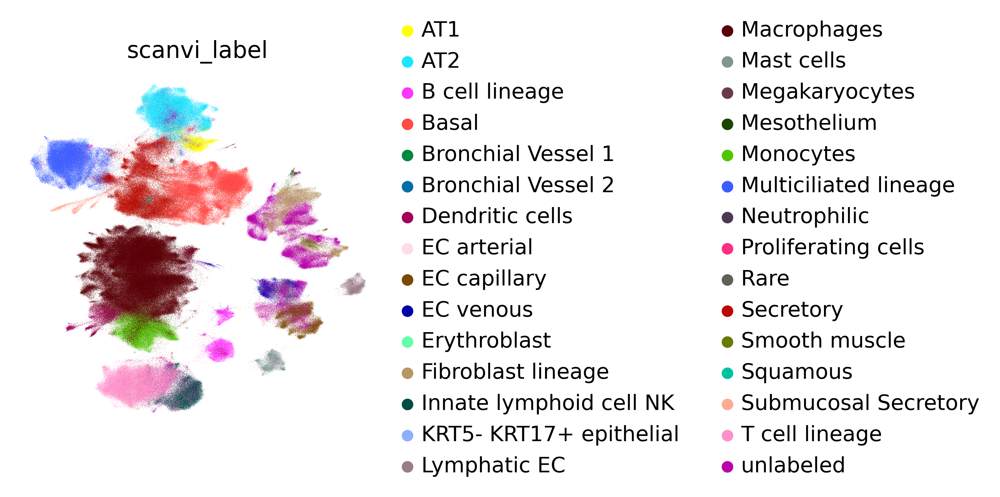

In [20]:
sc.pl.umap(combined_data_ref_hvg, color=cell_type_key, frameon=False)

In [21]:
scANVI_model_ref_hvg = sca.models.SCANVI.from_scvi_model(scvi_model_ref_hvg, unlabeled_category, adata=combined_data_ref_hvg)

In [22]:
scANVI_model_ref_hvg.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 186/200:  93%|█████████▎| 186/200 [8:59:22<40:35, 173.99s/it, loss=723, v_num=1]  


In [23]:
scANVI_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI_ref_hvg")

In [18]:
scANVI_model_ref_hvg = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/scANVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 30 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [19]:
print("Labelled Indices: ", len(scANVI_model_ref_hvg._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model_ref_hvg._unlabeled_indices))

Labelled Indices:  881795
Unlabelled Indices:  77584


In [20]:
combined_data_ref_hvg.obs["C_scANVI"] = scANVI_model_ref_hvg.predict(combined_data_ref_hvg)
combined_data_ref_hvg.obsm["X_scANVI"] = scANVI_model_ref_hvg.get_latent_representation(combined_data_ref_hvg)

In [27]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scANVI")
sc.tl.umap(combined_data_ref_hvg)

... storing 'C_scANVI' as categorical


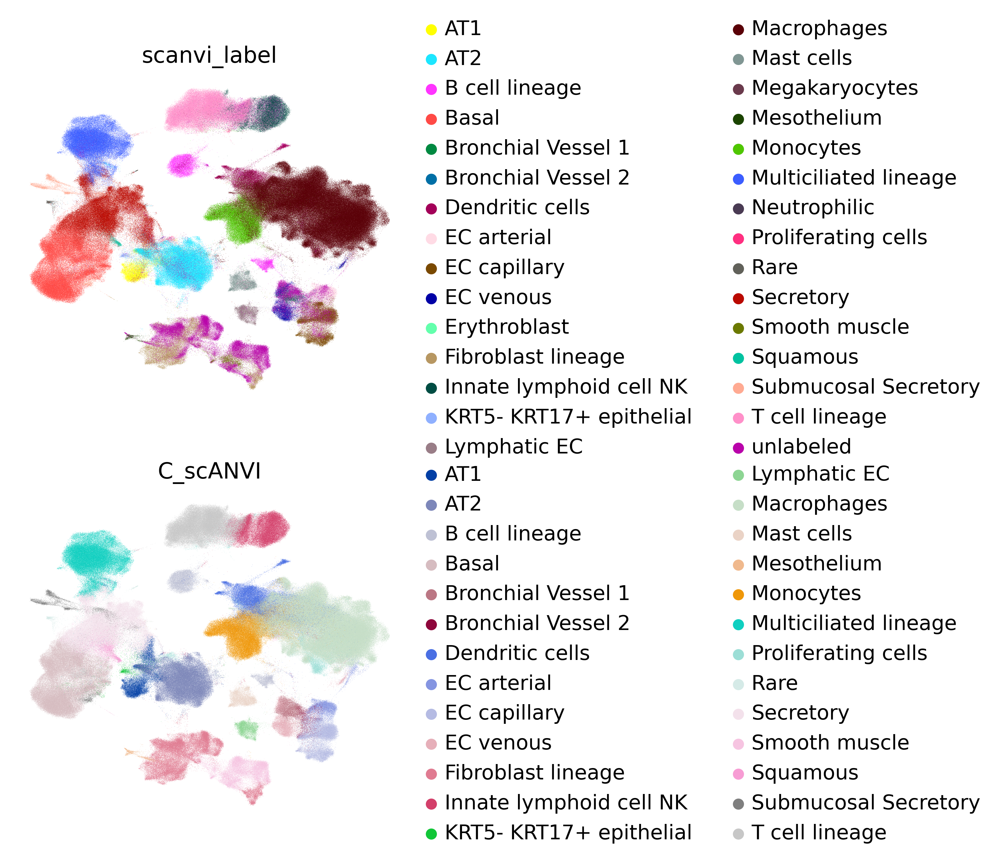

In [28]:
sc.pl.umap(combined_data_ref_hvg, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [29]:
df = combined_data_ref_hvg.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

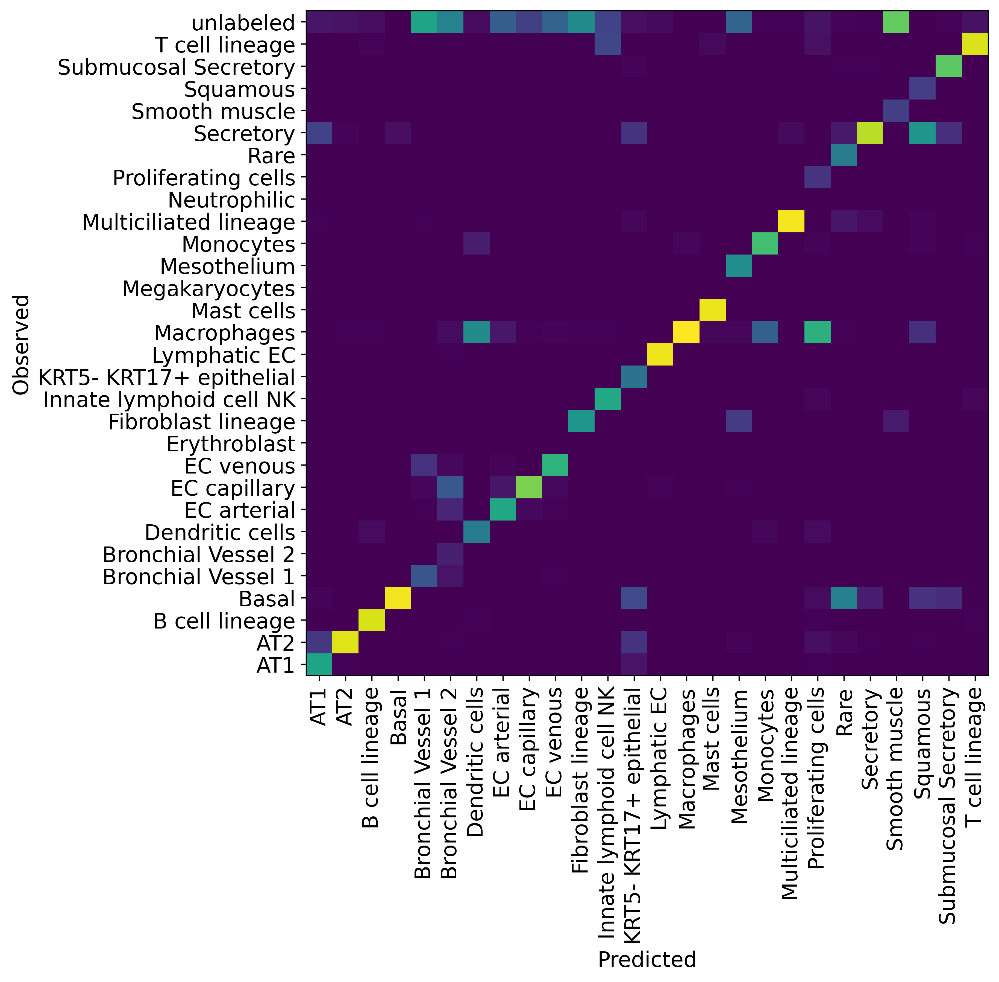

In [ ]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
combined_data_ref_hvg.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo_ref_hvg.h5ad")

## 2. scArches | Perform surgery 

### 2.1 Unlabeled scArches

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set all labels to unlabeled

In [16]:
scANVI_model_original = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", atlas_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [17]:
query_data.obs["scanvi_label_original"]=query_data.obs["scanvi_label"]

In [18]:
query_data.obs["scanvi_label"]=scANVI_model_original.unlabeled_category_

In [19]:
query_data_scArches = query_data[:,atlas_data.var.gene_ids].copy()

In [20]:
scArches_model = sca.models.SCANVI.load_query_data(
    query_data_scArches,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model._unlabeled_indices = np.arange(query_data_scArches.n_obs)
scArches_model._labeled_indices = []
print("Labelled Indices: ", len(scArches_model._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model._unlabeled_indices))

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 374495 cells, 2000 vars, 18       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
Labelled Indices:  0
Unlabelled Indices:  374495


In [21]:
scArches_model.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [2:03:34<00:00, 37.07s/it, loss=713, v_num=1]  


In [22]:
query_data_scArches_full = atlas_data.concatenate(query_data_scArches)
query_data_scArches_full.obs["C_scArches"] = scArches_model.predict(query_data_scArches_full)
query_data_scArches_full.obsm["X_scArches"] = scArches_model.get_latent_representation(query_data_scArches_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 959379 cells, 2000 vars, 18       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [23]:
sc.pp.neighbors(query_data_scArches_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_full)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scArches' as categorical


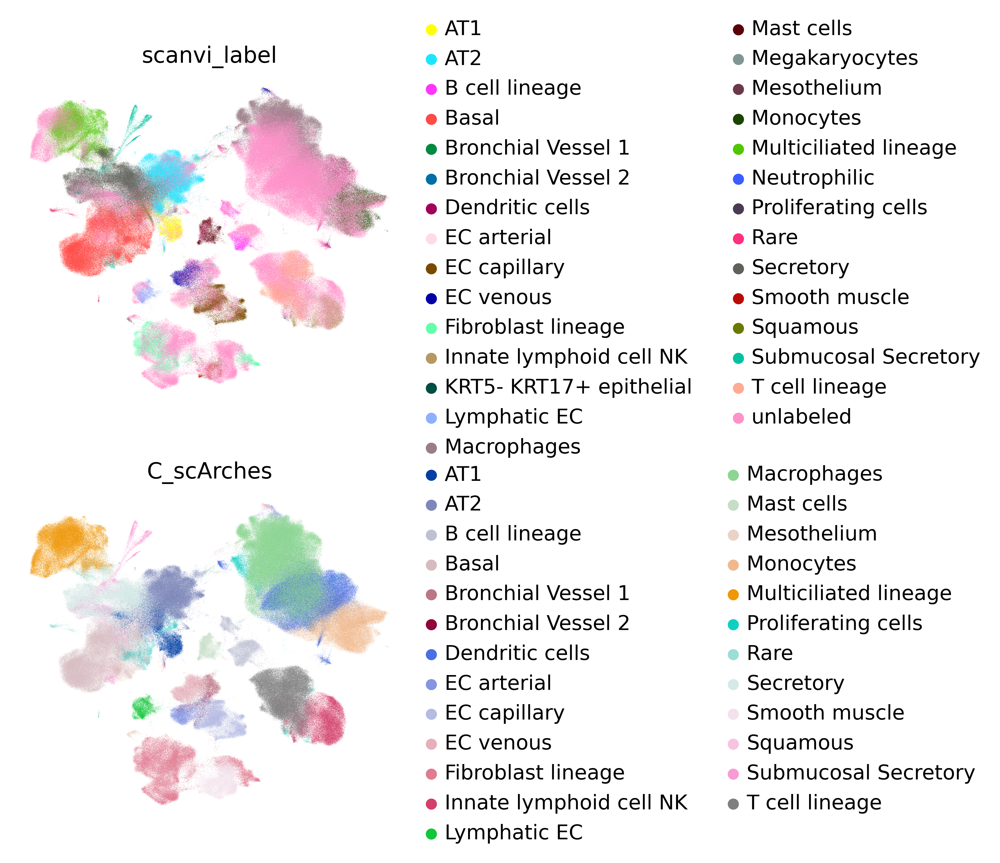

In [24]:
sc.pl.umap(query_data_scArches_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

In [25]:
df = query_data_scArches_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

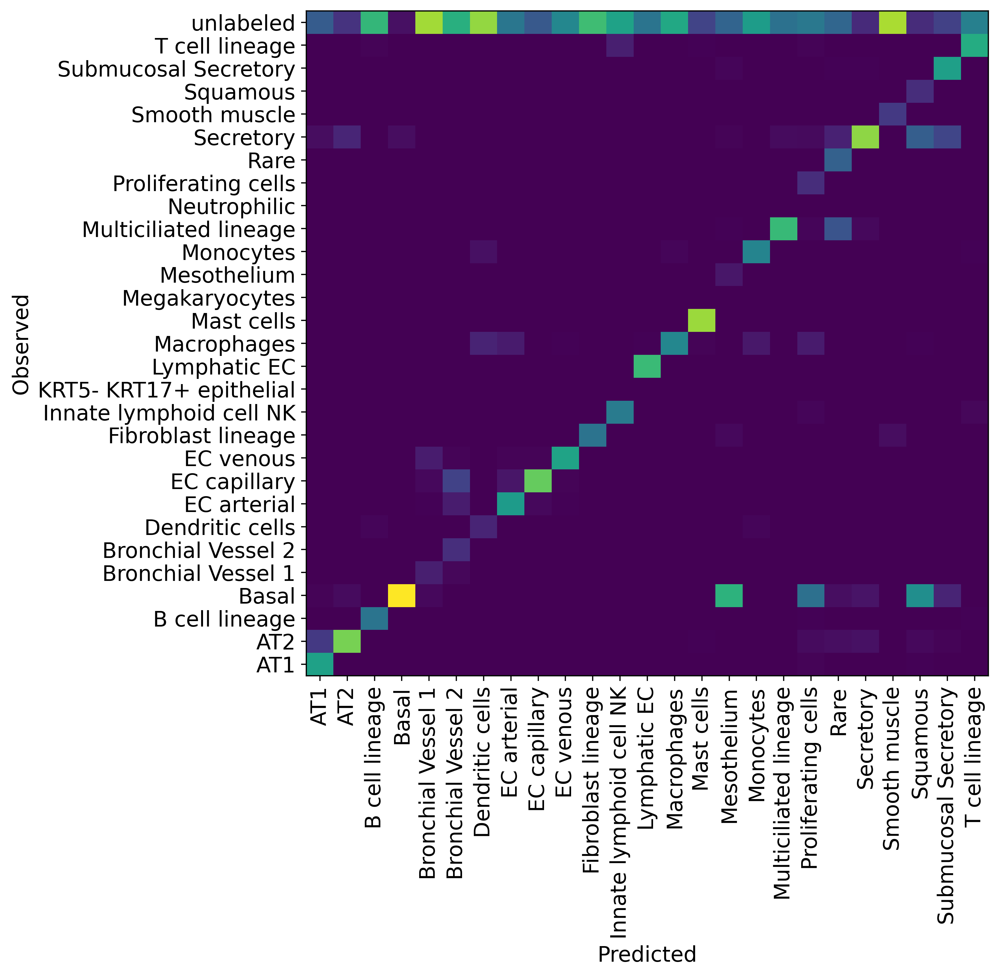

In [26]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
query_data_scArches_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")

### 2.2 Labeled scArches

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set labels to unlabeled which are not in the atlas

In [ ]:
mask_unlabeled = [x for x in set(query_data.obs.scanvi_label_original) if x not in set(atlas_data.obs.scanvi_label)]

In [ ]:
set(query_data.obs.scanvi_label_original)

In [ ]:
set(atlas_data.obs.scanvi_label)

In [ ]:
mask_unlabeled

In [ ]:
query_data.obs["scanvi_label"][query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = scANVI_model_original.unlabeled_category_

In [ ]:
query_data.obs["scanvi_label"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)] = query_data.obs["scanvi_label_original"][~query_data.obs["scanvi_label_original"].isin(mask_unlabeled)]

In [ ]:
query_data_scArches_labeled = query_data[:,atlas_data.var.gene_ids].copy()

In [ ]:
[x for x in set(query_data_scArches_labeled.obs.scanvi_label) if x not in set(atlas_data.obs.scanvi_label)]
# if empty set, then all labels in query data are in atlas data contained

In [ ]:
scArches_model_labeled = sca.models.SCANVI.load_query_data(
    query_data_scArches_labeled,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model_labeled._unlabeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]==scArches_model_labeled.unlabeled_category_))[0]
scArches_model_labeled._labeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]!=scArches_model_labeled.unlabeled_category_))[0]
print("Labelled Indices: ", len(scArches_model_labeled._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model_labeled._unlabeled_indices))

In [ ]:
scArches_model_labeled.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))
query_data_scArches_labeled.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation()

In [ ]:
query_data_scArches_labeled_full = atlas_data.concatenate(query_data_scArches_labeled)
query_data_scArches_labeled_full.obs["C_scArches"] = scArches_model_labeled.predict(query_data_scArches_labeled_full)
query_data_scArches_labeled_full.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation(query_data_scArches_labeled_full)

In [ ]:
sc.pp.neighbors(query_data_scArches_labeled_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_labeled_full)

In [ ]:
sc.pl.umap(query_data_scArches_labeled_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

In [ ]:
df = query_data_scArches_labeled_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

In [ ]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [ ]:
query_data_scArches_labeled_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_labeled_full.h5ad")

In [ ]:
sc.logging.print_versions()